# **Applied Data Analysis - Project Milestone P2**
## *How to be funny, for dummies.*

**<font size="4">Team: *JSON Derulo*</font>**<br>
- Adrián Fernández Lojo - adrian.fernandezlojo@epfl.ch
- Hanna Zwygart - hanna.zwygart@epfl.ch
- Jeremy Alexandre Serillon - jeremy.serillon@epfl.ch
- Mariem Maazoun - mariem.maazoun@epfl.ch
- Marina-Carmen Meredith Romero - marina.meredith@epfl.ch

Github repository: https://github.com/epfl-ada/ada-2025-project-json-derulo

<!-- 
Make sure to read the [P2_README.md](P2_README.md) file.
<br><br>

**<font size="4">Table of Content</font>**

0. [Introduction](#0.-Introduction) <br>
0.1. [Abstract](#01-abstract) <br>
0.2. [Problematic](#02-problematic) <br>
0.3. [Dataset Description](#03-dataset-description) <br>
1. [General Data Visualizations](#1-general-data-visualizations) <br>
1.1. [Global Overview](#11-global-overview) <br>
1.2. [Overview of Contest Data](#12-overview-of-contest-data) <br>
1.3. [Intra Contest Overview](#13-intra-contest-overview) <br>
2. [Data pre-processing & cleaning](#2-data-pre-processing--cleaning) <br>
2.1. [Data Wrangling (filter, transform, ...)](#21-data-wrangling-filter-transform-) <br>
2.2. [Dataset Augmentation (enrich and adding new data)](#22-dataset-augmentation-enrich-and-adding-new-data) <br>
3. [Theme Analysis](#3-theme-analysis)
4. [Structural Analysis](#4-structural-analysis)
5. [Semantic Analysis](#5-semantic-analysis)
6. [Context Analysis](#6-context-analysis)
7. [Conclusion](#7-conclusion) -->

## 0. Introduction



### 0.1. Abstract

_"A day without laughter is a day wasted"_ - Charlie Chaplin

Each week, the NewYorker magazine provides an original cartoon, with a missing caption. Readers are thus invited to not only caption that week's contest, but also rate the previous week's image. 

In recent years, meme culture, and internet culture overall, has consistently prioritized shorter, and trending jokes. Tweets, TikToks, and even indirectly related formats, are tending to become shorter and have visual support. This is one of the many factors that could define how an image supported joke lands.

In this project, we have decided to dive into the NewYorker's caption contest dataset, which will give us great insights into humour, one of the most complex forms of human communication. We aim to discover the themes, structures, semantics, context and other subtleties that make something "funny".

<!-- Being funny is generally defined as a deeply cultural, societal and even contextual skill. When looking at our dataset, naturally, the following questions emerged : How can funniness be quantified ? Is humor objective ? 
Humour is a good reflection of society. The NYT caricatures are iconic, and captures years of societal, political and even government changes. We were therefore naturally drawn towards this dataset. We thought it would be interesting to see the evolutions of these captions over multiple years, through COVID etc…
The story we would like to tell is the story of what defines a funny or unfunny joke.
How do people react to the semantics and structure of a joke?  In our opinion, we would expect certain themes or joke structure to work better than others.  -->

### 0.2. Problematic

**Main problematics** <br>
How can we qualify and quantify jokes in terms of themes, structures and semantics (type of joke)?  <!-- and context (image desc. + temporal) -->

**Research questions and directions**<br>
Based on the objectives presented in the abstract, we aim to tackle the following concrete questions : 

1. Theme analysis:<br>
   1.a) What themes have a tendency to be ranked better ?<br>
   1.b) How theme relationships work between image and their text prompt (one way, or two-way) ?

2. Structural analysis: <br>
   2.a) Keep it short and simple: Are shorter jokes actually funnier ?<br>
   2.b) Are jokes with specific punctuation and rythms more effective ?

3. Semantic analysis:<br>
   3.a) What type of jokes over or underperform ? More specifically, which of the following categories perform best : dark humor, irony, social commentary, wordplay or absurdity ?

4. Context analysis: [this reasearch question was dropped, see below why]<br>
   4.a) How do external factors influence Humor ? In particular, can we link trends found in the dataset to societal landmarks ? 
<!-- 
1. Theme analysis: <br>
1.a. What themes have a tendency to be ranked better? We have found a LLM method which could help answer this question.<br>
1.b. How theme relationships work between image and their text prompt (one way, or two-way)?<br>

2. Structural analysis:<br>
2.a. Keep it short and simple : Are shorter jokes funnier? Are they more eﬀective by their ‘simplicity’?<br>
2.b. Are jokes with specific punctuation, rythme, … are effective?<br>

3. Semantic analysis:<br>
3.a. What type of jokes over or underperform? Types of joke: dark humor, irony, social commentary, wordplay, absurdity … [Deceptive Humor Dataset (DHD)](https://arxiv.org/abs/2503.16031)

4. Context influence, how do external factors influence Humor? (enrich dataset)<br>
4.a. Actuality (polytical, environmental, …) [GDELT](http://data.gdeltproject.org/events/index.html)<br>
4.b. Who is the targeted public, location, age? [Paper1](https://www.pewresearch.org/politics/2012/09/27/section-4-demographics-and-political-views-of-news-audiences/#:~:text=Regular%20readers%20of%20the%20New,talk%20programs%2C%20have%20older%20audiences.), [Paper2](https://www.library.illinois.edu/infosci/is-publications/civilian-publications/the-new-yorker/)<br>
4.c. [Dropped] Does an image's complexity visually play a role?<br>

5. [Dropped] How well can NLP perform in these types of contexts ? -->


### 0.3. Dataset description

The NewYorker's caption contest dataset follows the structure depicted below:
```bash
.
├── contests.json
├── data/
│   ├── 510.csv
│   ├── 511.csv
│   ...
│   ├── 894.csv
│   └── 895.csv
└── images/
    ├── 510.jpg
    ├── 511.jpg
    ...
    ├── 894.jpg
    └── 895.jpg
```

The ```contest.json``` holds the following data: _image path_, corresponding .csv _data path_ & _metadata_. The _metadata_ is a dictionary containing: the number of captions (present in the corresponding .csv file), image locations description (e.g. "streets", "a field", "wedding", ...), images descriptions ("A man walks outside."), image uncanny descriptions, related questions & related Wikipedia entities.

The corresponding contest image csv files, e.g. ```510.csv```, hold the following keys: <br>
funniness rank 'rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny' & 'funny'.


## 1. General Data Visualizations

In [7]:
# General
import os
from pathlib import Path

# data manipulation
import json
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap


# Interactive Jupyter
from IPython.display import display

# Custom utility python files
import utils.visualization as viz # custom visualization utils in '/utils/visualization.py'

In [2]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:", PROJECT_ROOT)
print("FIGURES_DIR:", FIGURES_DIR)
print("\nDATA_DIR:", DATA_DIR)
print("JSON_DIR:", JSON_DIR)
print("CSV_DIR:", CSV_DIR)
print("IMG_DIR:", IMG_DIR)

Project path setup:
PROJECT_ROOT: c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo
FIGURES_DIR: c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\figures

DATA_DIR: c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR: c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR: c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
IMG_DIR: c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images


In [3]:
# Visualization settings
cst_cmap_purple = ListedColormap(["#500091"])   # dark purple

### 1.1. Global Overview

Let us take a look at our raw dataset. Feel free to play with the slider to visualize different contest images and corresponding metadatas (if any).

In [3]:
# Load the JSON file => pandas DataFrame
file_path = str(JSON_DIR)
with open(file_path, "r") as file:
    contests = json.load(file)
contests_df = pd.DataFrame(contests)

# Visualize the contests with interactive viewer
viewer = viz.make_contest_viewer(contests_df, file_path)
display(viewer)

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\mered\\OneDrive\\Escritorio\\Marina\\MA2\\ADA\\ada-2025-project-json-derulo\\data\\newyorker_caption_contest\\contests.json'

Once you have selected a contest ID with the slider, run the next cell to visualize some plots of the corresponding .CSV file.

In [4]:
contest_id = int(viewer.slider.value)
print("Current selected 'contest_id' =", contest_id)

# Load corresponding CSV file
contest_row = contests_df[contests_df["contest_id"] == contest_id]
if not contest_row.empty:
    csv_rel_path = contest_row.iloc[0]["data"]
    csv_path = os.path.join(os.path.dirname(file_path), csv_rel_path)
    if os.path.exists(csv_path):
        df_current = pd.read_csv(csv_path)
        viz.plot_df_pairgrid(df_current, cols=["mean","precision","votes", "not_funny",
                                               "somewhat_funny", "funny"],
                             trace="none", cmap=cst_cmap_purple, figsize=(8,8),
                             include_upper=False, diagonal="name")
    else:
        print(f"CSV file not found at {csv_path}")
else:
    print(f"No contest found for contest_id {contest_id}")

NameError: name 'viewer' is not defined

In [6]:
print(contests_df.count())

contest_id    384
image         384
data          384
metadata      240
dtype: int64


### 1.2. Overview of Contest Data (```contests.json``` file)

- missing metadatas (dictionaries): 144
- 2 missing contest: 525 & 540

In [7]:
# check missing contest (in the interval 510-895)
missing_contest = []
missing_csv = []
for id in range(510, 896):
    # missing contest id in json file
    if id not in contests_df['contest_id'].values:
        missing_contest.append(id)
    # missing csv file in DATA_DIR
    csv_path = CSV_DIR / f"{id}.csv"
    if not csv_path.exists():
        missing_csv.append(id)
        
print("Missing contest IDs in json file:", missing_contest)
print("Contests with missing CSV files in DATA_DIR:", missing_csv)

Missing contest IDs in json file: [525, 540]
Contests with missing CSV files in DATA_DIR: [525, 540]


In [8]:
# check missing metadata for each (present) contest id
missing_metadata = contests_df[contests_df['metadata'].isnull()]
print(f"Count of missing metadata: {len(missing_metadata)}")
print("Contest IDs with missing metadata:", missing_metadata['contest_id'].tolist())

Count of missing metadata: 144
Contest IDs with missing metadata: [527, 564, 588, 597, 605, 615, 644, 647, 656, 657, 670, 714, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 785, 786, 787, 788, 789, 790, 791, 792, 793, 794, 795, 796, 797, 798, 799, 800, 801, 802, 803, 804, 805, 806, 807, 808, 809, 810, 811, 812, 813, 814, 815, 816, 817, 818, 819, 820, 821, 822, 823, 824, 825, 826, 827, 828, 829, 830, 831, 832, 833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 848, 849, 850, 851, 852, 853, 854, 855, 856, 857, 858, 859, 860, 861, 862, 863, 864, 865, 866, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888, 889, 890, 891, 892, 893, 894, 895]


### 1.3. Intra Contest Overview (.csv files)

- corrupted rows: in all ... we have 64'007 corrupted rows in all of the .csv files for a total of 2'292'677 rows. Here is an example below of corrupted rows in file ```523.csv```, row n°492 to n°506. As we can not make an assumption of which number is exploitable, we decided to exclude those lines. For more details, please refer to section [2.1 Data Wrangling](#21-data-wrangling-filter-transform-).  <br><br>
    <img src="../../figures/documentation/corrupted-csv.png" width="600"/>
<br><br>
- missing 'rank' columns in some .csv file such as ```663.csv```. Although the 'rank' column was missing, the order of the .csv was preserved so we added it.


## 2. Data pre-processing & cleaning

Let's 

### 2.1. Data Wrangling (filter, transform, ...)

Contest Metadata missing from contest number ```764``` until the end. 2 missing contests: ```525``` and ```540```. 
=> reasons: filter data captions that are sensitive or sensitive context.

To correct the corrupted rows problem, we used two criterias which can be consulted in the function '```check_corruption()```' from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py).

In [ ]:
# check_corruption() here

### 2.2. Dataset Augmentation (enrich and adding new data)

## 3. Theme Analysis

## 4. Structural Analysis

In [2]:
import pandas as pd
from ipywidgets import interact, IntSlider
from IPython.display import display, Markdown, Image
from pathlib import Path
import string
import re
import contractions
import seaborn as sns
import scipy
import utils.structural_analysis as ut
from scipy.stats import pearsonr, spearmanr, ttest_ind, mannwhitneyu 
import sys 
from collections import Counter
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
import seaborn as sns
from scipy.stats import pearsonr, spearmanr


### 4.1 Data handling, cleaning up for the structural analysis

**Opening of the csv data**

In [3]:
base_path = r"C:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\newyorker_caption_contest\data"

df = ut.load_all_contest_data(base_path, start_id=510, end_id= 895)

Missing files for contest IDs: [525, 540]
Successfully loaded 384 files
Total rows: 2292678


**Make the captions more fluid by:**
- erasing unnecessary punctuations 
- lowercase all the captions 
- handling contractions to normalise all the captions 
        -> necessary for comparison 

In [4]:
# check for missing values and fill NaN w/ empty string or remove them
print(f"missing values in caption: {df['caption'].isna().sum()}")
df["caption"] = df["caption"].fillna("")

# erase unnecessary punctuations :
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)

# lowercase : 
df["caption"] = df["caption"].str.lower()

# contractions :
df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))   

print(df["caption"].head()) # check

missing values in caption: 50
0           i am a congressman  obstruction is my job 
1    i am what they mean when they say  'the middle...
2                    does this suit make me look flat 
3    when the right woman comes along  i will know it 
4    i used to lie in the gutter  but then i quit d...
Name: caption, dtype: object


### 4.2 Are longer jokes funnier than shorter ones? What about jokes with more complex vocabulary?

**How many words and characters are there in each caption ?**

In [5]:
# words
df["word_counts"] = [len(line.split()) for line in df["caption"]]

# characters 
df["length"] = [len(line) for line in df["caption"]]

# average of words and characters
print(f"avg word count: {df['word_counts'].mean():.2f}")
print(f"avg character count: {df['length'].mean():.2f}")
print(f"data set size: {len(df)} captions")

avg word count: 10.64
avg character count: 53.83
data set size: 2292678 captions


*Plotting and correlation:*


correlation w/ funny Score:
# of words correlation: -0.042 (p-value: 0.000)
# of characters correlation: -0.047 (p-value: 0.000)


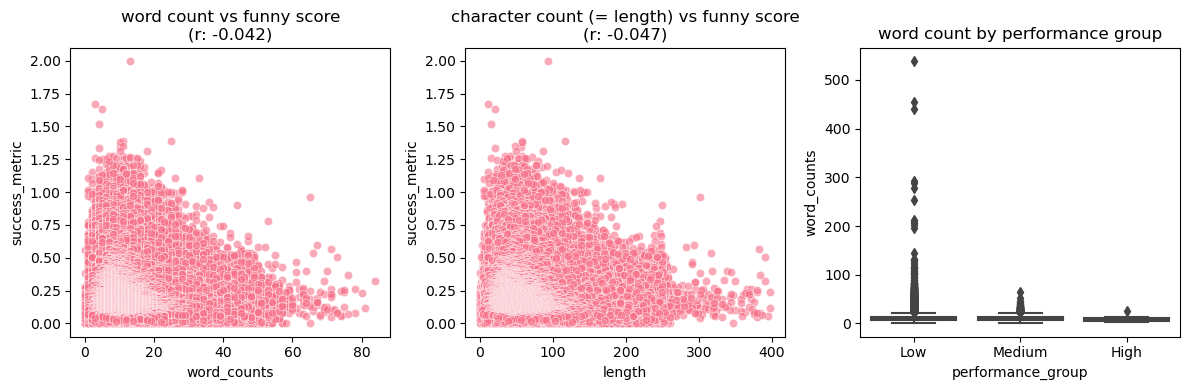

In [10]:
# style of plot
plt.style.use('default')
sns.set_palette("husl")

# scores
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny'] # this is for each caption 

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

# weighted average (2 for funny, 1 for somewhat_funny, 0 for not_funny)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']
df['success_metric'] = df['funny_score_weighted']

# correlation analysis 
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\ncorrelation w/ funny Score:")
print(f"# of words correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"# of characters correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

df_filtered = df[(df['word_counts'] <= 100) & (df['length'] <= 400)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_filtered, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'word count vs funny score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df_filtered, x='length', y='success_metric', alpha=0.6)
plt.title(f'character count (= length) vs funny score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('word count by performance group')

plt.tight_layout()
plt.show()



*Statistical testing*

In [11]:
# statistical test for performance comparison & word count performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance comparison:")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nword count comparison:")
print(f"top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

print(f"\nlength count comparison:")
print(f"top performers: {top_captions['length'].mean():.1f} ± {top_captions['length'].std():.1f}")
print(f"bottom performers: {bottom_captions['length'].mean():.1f} ± {bottom_captions['length'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"t-test p-value words: {p_val:.4f}")

t_stat, p_val = ttest_ind(top_captions['length'], bottom_captions['length'])
print(f"t-test p-value characters: {p_val:.4f}")



performance comparison:
top 20% cutoff: 0.297 (458769 captions)
bottom 20% cutoff: 0.118 (463873 captions)

word count comparison:
top performers: 10.3 ± 4.6
bottom performers: 11.0 ± 5.8

length count comparison:
top performers: 52.1 ± 23.5
bottom performers: 56.0 ± 29.9
t-test p-value words: 0.0000
t-test p-value characters: 0.0000


*Interpretation:*

| **Metric** | **Top 20%** | **Bottom 20%** |
|-----------|-----------|--------------|
| Mean word count | 10.3 | 11.0 |
| Standard deviation (word) | 4.6 | 5.8 |
| Mean character count | 52.1 | 56.0 |
| Standard deviation (characters) | 23.5 | 29.9 |

In both counting cases (words and characters) the t-test p-value is < 0.0001, which means that the the difference in count between the two types of performers is statistically significant, in other words, the probability that this difference happened by random chance is less than 0.0001%. 

Therefore, knowing this, we can say that the top performing captions tend to be shorter in words and characters than the bottom performing ones.This conclusion is interesting, and context is necessary: it looks like the practical difference is small but because we are working with a huge amount of captions, this difference is statistically significant.  

These observations can be done also through plot visualisation, where we can see that the captions that clearly have better scores are those that are shorter.

**Do some words correlate w/ higher scores?**

*Analysis of vocabulary richness using TTR (type-token ratio) aka # of unique words / total words*

Then we will analyse whether winning prompts use a more diverse vocabulary or not

In [12]:
# calculation of vocabulary richness metrics

# check if we already have these columns & remove them if they exist (in case of problems)
columns_to_remove = ['ttr', 'unique_words', 'total_words']
existing_cols = [col for col in columns_to_remove if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# calculate vocab richness for all captions
vocab_metrics = ut.calculate_vocabulary_richness(df['caption'], remove_stopwords=True)

# new columns to the main DataFrame
df = pd.concat([df, vocab_metrics], axis=1)

# some stats
print(f"average TTR: {df['ttr'].mean():.3f}")
print(f"average unique words per caption: {df['unique_words'].mean():.1f}")
print(f"average total words per caption: {df['total_words'].mean():.1f}")
print(f"dataset size: {len(df)} captions")


average TTR: 0.989
average unique words per caption: 4.9
average total words per caption: 5.0
dataset size: 2292678 captions


In [13]:
# comparison of top & bottom performers
top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance groups")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

print(f"\nvocab richness comparison")
print("top performers:")
print(f"  TTR: {top_captions['ttr'].mean():.3f} ± {top_captions['ttr'].std():.3f}")
print(f"  Unique words: {top_captions['unique_words'].mean():.1f} ± {top_captions['unique_words'].std():.1f}")
print(f"  Total words: {top_captions['total_words'].mean():.1f} ± {top_captions['total_words'].std():.1f}")

print("\nbottom:")
print(f"  TTR: {bottom_captions['ttr'].mean():.3f} ± {bottom_captions['ttr'].std():.3f}")
print(f"  Unique words: {bottom_captions['unique_words'].mean():.1f} ± {bottom_captions['unique_words'].std():.1f}")
print(f"  Total words: {bottom_captions['total_words'].mean():.1f} ± {bottom_captions['total_words'].std():.1f}")




performance groups
top 20% cutoff: 0.297 (458769 captions)
bottom 20% cutoff: 0.118 (463873 captions)

vocab richness comparison
top performers:
  TTR: 0.990 ± 0.060
  Unique words: 4.7 ± 2.2
  Total words: 4.8 ± 2.3

bottom:
  TTR: 0.987 ± 0.068
  Unique words: 5.2 ± 2.8
  Total words: 5.3 ± 2.9



T-TESTS)
TTR (p-value) = 0.0000 ***
Unique words (p-value) = 0.0000 ***
Total words (p-value) = 0.0000 ***

correlation w/ success metric
TTR correlation: 0.013 (p-value: 0.0000)
unique words correlation: -0.058 (p-value: 0.0000)
total words correlation: -0.059 (p-value: 0.0000)


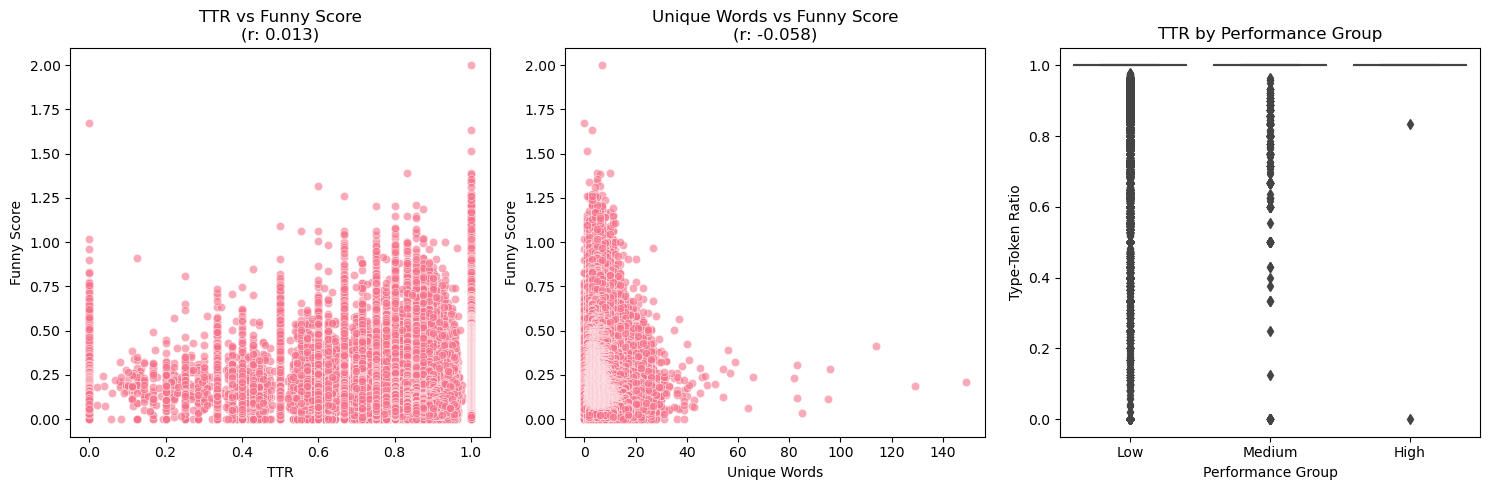

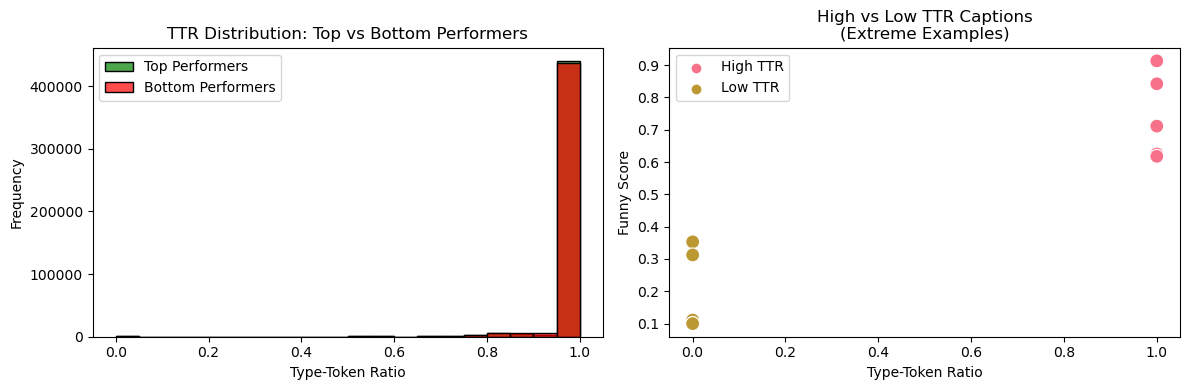

In [17]:
# stat tests 
t_stat_ttr, p_val_ttr = ttest_ind(top_captions['ttr'], bottom_captions['ttr'])
t_stat_unique, p_val_unique = ttest_ind(top_captions['unique_words'], bottom_captions['unique_words'])
t_stat_total, p_val_total = ttest_ind(top_captions['total_words'], bottom_captions['total_words'])

print(f"\nT-TESTS)")
print(f"TTR (p-value) = {p_val_ttr:.4f} {'***' if p_val_ttr < 0.001 else '**' if p_val_ttr < 0.01 else '*' if p_val_ttr < 0.05 else 'ns'}")
print(f"Unique words (p-value) = {p_val_unique:.4f} {'***' if p_val_unique < 0.001 else '**' if p_val_unique < 0.01 else '*' if p_val_unique < 0.05 else 'ns'}")
print(f"Total words (p-value) = {p_val_total:.4f} {'***' if p_val_total < 0.001 else '**' if p_val_total < 0.01 else '*' if p_val_total < 0.05 else 'ns'}")

# correlation analysis 
corr_ttr, p_corr_ttr = pearsonr(df['ttr'], df['success_metric'])
corr_unique, p_corr_unique = pearsonr(df['unique_words'], df['success_metric'])
corr_total, p_corr_total = pearsonr(df['total_words'], df['success_metric'])

print(f"\ncorrelation w/ success metric")
print(f"TTR correlation: {corr_ttr:.3f} (p-value: {p_corr_ttr:.4f})")
print(f"unique words correlation: {corr_unique:.3f} (p-value: {p_corr_unique:.4f})")
print(f"total words correlation: {corr_total:.3f} (p-value: {p_corr_total:.4f})")

ut.plot_linguistic_metrics(df, top_captions, bottom_captions, corr_ttr, corr_unique)


*Interpretation of the results:* 

we can observe that the TTR difference is minimal (there is only a 0.975 difference, which is a 0.9% relative difference). Knowing that p = 0.02, this difference is statistically significant (it's not from random noise) but it is oractically meaningless (the effect is not large enough to matter here). We can also see that both groups have a high TTR, meaning nearly all words are unique, so there is not vocabulary influence on humour. 

## 5. Semantic Analysis

## 6. Context Analysis

## 7. Conclusion